# 1일차 EDA — 바이어 연체 현황

- 원본: `data/day1/d1_buyers_raw.xlsx` (읽기만 한다) · 결제조건 코드표: `workbench/day1/outputs/d1_code_table.csv`
- 정리 규칙과 코드: `scripts/d1_clean_buyers.py` (R1~R11). 분석용 표는 메모리에서만 만든다
- 연체 바이어 = `max_dpd_days > 0`. 연체일수를 알 수 없는 바이어(`확인중` · `-`)는 비율의 분모에서 뺀다
- 차트 PNG: `workbench/day1/outputs/charts/` · 해석: `workbench/day1/outputs/d1_eda_notes.md`

In [1]:
# 1. 분석용 표 만들기 — 경로는 저장소 맨 위 폴더 기준
import os
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root / "scripts"))

import pandas as pd
from d1_clean_buyers import load_clean_buyers, overdue_rate

df = load_clean_buyers()
known = df["dpd"].notna()
print(f"원본 {df.attrs['n_raw_rows']}행 → 중복 {df.attrs['n_dropped_dup']}행 제외 → 분석용 {len(df)}행")
print(f"연체 바이어(dpd > 0): {int(df['is_overdue'].fillna(False).sum())} / dpd 확인 {int(known.sum())}")
print("dpd 모름(분모 제외):", df.loc[~known, ["buyer_id", "max_dpd_days"]].values.tolist())
print("글자에서 숫자로 바꾼 dpd:", df.loc[df["max_dpd_days"].map(type).eq(str) & known, ["buyer_id", "max_dpd_days", "dpd"]].values.tolist())
print("결제방식:", df["pay_method"].value_counts().to_dict())
print("통화 빈칸(확인 필요):", df.loc[df["currency"].isna(), ["buyer_id", "ar_currency"]].values.tolist())
print("근사 금액(약):", df.loc[df["amount_approx"], "buyer_id"].tolist())
print("슬래시 날짜 일·월 모호:", int(df["since_date_ambiguous"].sum()), "건")
df[["buyer_id", "country_std", "payment_terms_raw", "pay_method", "max_dpd_days", "dpd", "is_overdue",
    "ar_balance", "ar_balance_num", "ar_currency", "currency", "since_date", "since"]].head(8)

원본 153행 → 중복 3행 제외 → 분석용 150행
연체 바이어(dpd > 0): 25 / dpd 확인 148
dpd 모름(분모 제외): [['B058', '-'], ['B066', '확인중']]
글자에서 숫자로 바꾼 dpd: [['B048', '90일', 90.0], ['B147', '381 days', 381.0]]
결제방식: {'OA': 87, 'DA': 24, 'TT_ADV': 12, 'LC_SIGHT': 10, 'TT_SPLIT_30_70': 8, 'DP': 4, 'LC_USANCE': 4, '검토 필요': 1}
통화 빈칸(확인 필요): [['B079', '¥'], ['B080', '¥']]
근사 금액(약): ['B008', 'B068']
슬래시 날짜 일·월 모호: 14 건


,buyer_id,country_std,payment_terms_raw,pay_method,max_dpd_days,dpd,is_overdue,ar_balance,ar_balance_num,ar_currency,currency,since_date,since
0,B001,네덜란드,T/T 90 DAYS AFTER B/L,OA,0,0.0,False,23730,23730.0,EUR,EUR,2013.12.9,2013-12-09
1,B002,중국,OA90,OA,0,0.0,False,"USD 10,070",10070.0,USD,USD,2020-09-14,2020-09-14
2,B003,인도네시아,D/A 90,DA,0,0.0,False,0,0.0,USD,USD,Jun 27 2018,2018-06-27
3,B004,이집트,Confirmed L/C at sight,LC_SIGHT,0,0.0,False,0,0.0,USD,USD,Jun 20 2024,2024-06-20
4,B005,베트남,T/T 90 days after B/L,OA,13,13.0,True,346360,346360.0,usd,USD,2023.7.21,2023-07-21
5,B006,말레이시아,O/A 30,OA,0,0.0,False,0,0.0,USD,USD,29/04/2014,2014-04-29
6,B007,네덜란드,O/A 90,OA,0,0.0,False,NaN,<NA>,EUR,EUR,Jan 20 2017,2017-01-20
7,B008,독일,60 days O/A,OA,31,31.0,True,NaN,<NA>,EUR,EUR,13/07/2025,2025-07-13


In [2]:
# 2. 차트 공통 설정 — 한글 글꼴(tools/fonts/NanumGothic-Regular.ttf) · 색 · 저장 폴더
import matplotlib.pyplot as plt
from matplotlib import font_manager

FONT = root / "tools/fonts/NanumGothic-Regular.ttf"
font_manager.fontManager.addfont(FONT)
SURFACE, INK, MUTED, GRID, BLUE = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0", "#2a78d6"
plt.rcParams.update({
    "font.family": font_manager.FontProperties(fname=FONT).get_name(),
    "axes.unicode_minus": False,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})
CHARTS = root / "workbench/day1/outputs/charts"
CHARTS.mkdir(parents=True, exist_ok=True)
print("글꼴:", plt.rcParams["font.family"], "· 저장 폴더:", CHARTS.relative_to(root))

글꼴: ['NanumGothic'] · 저장 폴더: workbench\day1\outputs\charts


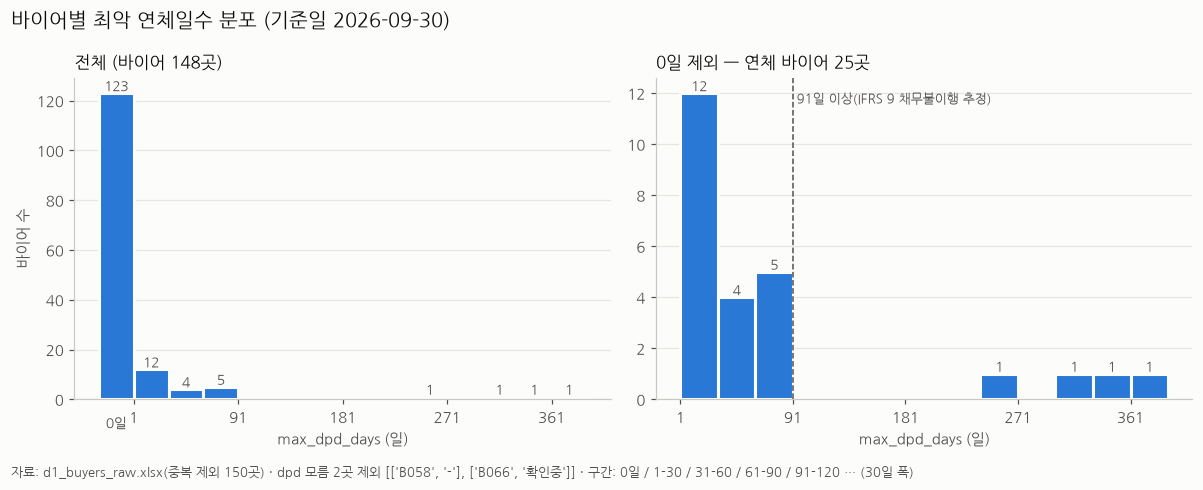

aging 구간(사전 codes 시트 기준): {'Current(0)': 123, '1-30': 12, '31-60': 4, '61-90': 5, '91+': 4}
통계(0일 제외): 중앙값 31.0 · 평균 81.0 · 최대 381.0
91일 이상: [['B044', '태국', 'DA', 355.0], ['B071', '대만', 'OA', 269.0], ['B083', '미국', 'OA', 305.0], ['B147', '태국', 'DA', 381.0]]


In [3]:
# 3. 차트 1 — max_dpd_days 분포(전체 · 0일 제외). dpd 모름 2곳은 제외
# 구간 경계는 사전 aging 구간(0 · 1-30 · 31-60 · 61-90 · 91+)과 맞춘다: 0일만 한 막대, 그 뒤는 1일부터 30일 폭
import numpy as np

dpd = df["dpd"].dropna().astype(float)
pos = dpd[dpd > 0]
unknown = df.loc[df["dpd"].isna(), ["buyer_id", "max_dpd_days"]].values.tolist()
bins_pos = np.arange(1, dpd.max() + 31, 30)          # [1,31) [31,61) [61,91) [91,121) ...
bins_all = np.concatenate([[-29], bins_pos])         # 맨 앞 [-29,1) 막대에는 0일만 들어간다

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, s, b, title in [(axes[0], dpd, bins_all, f"전체 (바이어 {len(dpd)}곳)"),
                        (axes[1], pos, bins_pos, f"0일 제외 — 연체 바이어 {len(pos)}곳")]:
    counts, _, _ = ax.hist(s, bins=b, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("max_dpd_days (일)")
    ax.set_xticks(bins_pos[::3])
    ax.grid(axis="x", visible=False)
    for x, c in zip(b[:-1], counts):
        if c:
            ax.text(x + 15, c, f"{int(c)}", ha="center", va="bottom", fontsize=9, color=MUTED)
axes[0].text(-14, -0.09, "0일", transform=axes[0].get_xaxis_transform(), ha="center", fontsize=9, color=MUTED)
axes[0].set_ylabel("바이어 수")
axes[1].axvline(91, color=MUTED, linestyle="--", linewidth=1)
axes[1].text(94, axes[1].get_ylim()[1] * 0.92, "91일 이상(IFRS 9 채무불이행 추정)", fontsize=8.5, color=MUTED)
fig.suptitle("바이어별 최악 연체일수 분포 (기준일 2026-09-30)", x=0.01, ha="left", fontsize=13)
fig.text(0.01, -0.03, f"자료: d1_buyers_raw.xlsx(중복 제외 {len(df)}곳) · dpd 모름 {len(unknown)}곳 제외 {unknown} · "
         "구간: 0일 / 1-30 / 31-60 / 61-90 / 91-120 … (30일 폭)", fontsize=8.5, color=MUTED)
fig.tight_layout()
fig.savefig(CHARTS / "d1_chart1_dpd_hist.png")
plt.show()

bucket = pd.cut(dpd, [-1, 0, 30, 60, 90, np.inf], labels=["Current(0)", "1-30", "31-60", "61-90", "91+"])
print("aging 구간(사전 codes 시트 기준):", bucket.value_counts().sort_index().to_dict())
print("통계(0일 제외): 중앙값", pos.median(), "· 평균", round(pos.mean(), 1), "· 최대", pos.max())
print("91일 이상:", df.loc[df["dpd"] >= 91, ["buyer_id", "country_std", "pay_method", "dpd"]].values.tolist())

**차트 1 해석** (숫자는 바로 위 셀 출력)
1. 연체일수를 아는 148곳 중 123곳(83.1% = 123 ÷ 148)은 연체가 없고, 연체 바이어는 25곳(16.9% = 25 ÷ 148)이다.
2. 연체 바이어 25곳 중 12곳은 1–30일, 9곳은 31–90일이다. 중앙값은 31일인데 평균은 81일이라, 소수의 장기 연체가 평균을 끌어올린다.
3. 91일 이상은 4곳(B147 태국 DA 381일 · B044 태국 DA 355일 · B083 미국 OA 305일 · B071 대만 OA 269일)이고, 모두 269일 이상이다. 일반적인 지연이 아니라 회수 불능 여부를 개별로 점검해야 할 대상이다.

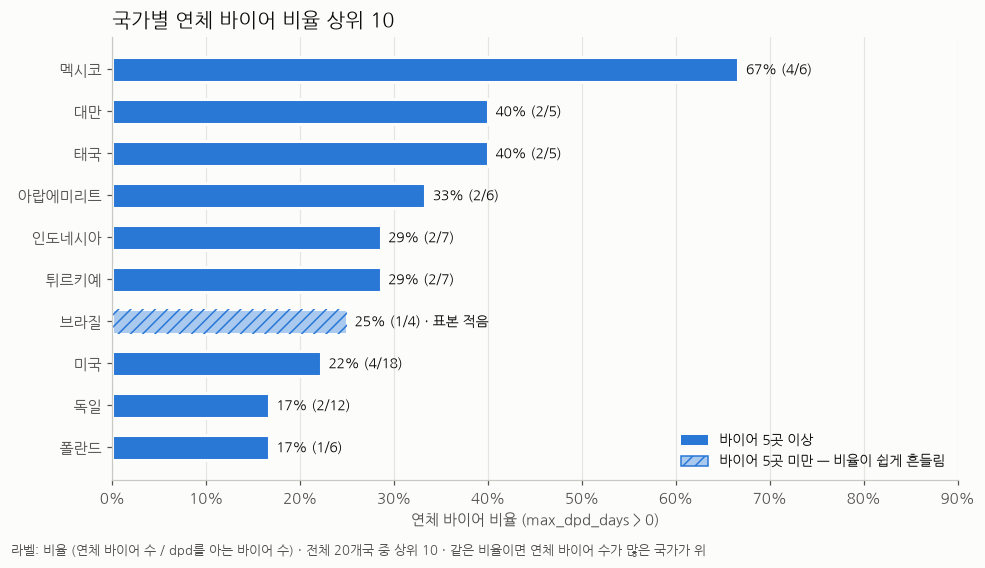

전체 평균 연체 비율: 16.9%


,바이어 수,dpd 모름,연체 바이어 수,분모(dpd 확인),연체 비율
country_std,,,,,
멕시코,6,0,4,6,66.7%
대만,5,0,2,5,40.0%
태국,5,0,2,5,40.0%
아랍에미리트,7,1,2,6,33.3%
인도네시아,7,0,2,7,28.6%
튀르키예,7,0,2,7,28.6%
브라질,4,0,1,4,25.0%
미국,18,0,4,18,22.2%
독일,12,0,2,12,16.7%


In [4]:
# 4. 차트 2 — 국가별 연체 바이어 비율 상위 10. 분모 = dpd를 아는 바이어, 5곳 미만 국가는 빗금 + '표본 적음'
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

MIN_N = 5
by_country = overdue_rate(df, "country_std")
top = by_country.sort_values(["연체 비율", "연체 바이어 수", "분모(dpd 확인)"], ascending=False).head(10)
small = top["분모(dpd 확인)"] < MIN_N

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(top))[::-1]  # 1위가 맨 위
ax.barh(y, top["연체 비율"], height=0.6, color=np.where(small, "#a9c9ef", BLUE),
        hatch=None, edgecolor=SURFACE, linewidth=2)
for yi, (name, r) in zip(y, top.iterrows()):
    if r["분모(dpd 확인)"] < MIN_N:
        ax.barh(yi, r["연체 비율"], height=0.6, color="none", edgecolor=BLUE, hatch="///", linewidth=0)
    note = " · 표본 적음" if r["분모(dpd 확인)"] < MIN_N else ""
    ax.text(r["연체 비율"] + 0.008, yi, f"{r['연체 비율']:.0%} ({int(r['연체 바이어 수'])}/{int(r['분모(dpd 확인)'])}){note}",
            va="center", fontsize=9, color=INK)
ax.set_yticks(y, top.index)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, top["연체 비율"].max() * 1.35)
ax.grid(axis="y", visible=False)
ax.set_xlabel("연체 바이어 비율 (max_dpd_days > 0)")
ax.legend(handles=[Patch(facecolor=BLUE, label=f"바이어 {MIN_N}곳 이상"),
                   Patch(facecolor="#a9c9ef", edgecolor=BLUE, hatch="///", label=f"바이어 {MIN_N}곳 미만 — 비율이 쉽게 흔들림")],
          loc="lower right", fontsize=9, frameon=False)
ax.set_title("국가별 연체 바이어 비율 상위 10", loc="left", fontsize=13)
fig.text(0.01, -0.02, f"라벨: 비율 (연체 바이어 수 / dpd를 아는 바이어 수) · 전체 {by_country.shape[0]}개국 중 상위 10 · "
         "같은 비율이면 연체 바이어 수가 많은 국가가 위", fontsize=8.5, color=MUTED)
fig.tight_layout()
fig.savefig(CHARTS / "d1_chart2_country_overdue.png")
plt.show()

print("전체 평균 연체 비율:", f"{df['is_overdue'].fillna(False).sum() / df['dpd'].notna().sum():.1%}")
by_country.sort_values(["연체 비율", "연체 바이어 수"], ascending=False).style.format({"연체 비율": "{:.1%}"})

**차트 2 해석** (전체 평균 연체 비율 16.9% = 25 ÷ 148)
1. 멕시코가 67%(4/6)로 가장 높고, 연체 4곳은 모두 OA다(5 · 36 · 48 · 74일). 이어서 대만 · 태국 40%(2/5), 아랍에미리트 33%(2/6) 순이다.
2. 비율보다 연체 길이가 더 큰 문제인 곳이 있다. 태국은 연체 2곳이 모두 DA 장기 연체(355 · 381일)이고, 대만은 1곳이 OA 269일이다.
3. 5곳 미만 표시는 브라질(1/4) 하나뿐이다. 하지만 5곳 이상인 국가도 대부분 5~7곳이라, 바이어 1곳 차이로 비율이 14~20%p(1/7 ~ 1/5) 움직인다. 국가 위험의 근거로 쓰기에는 약하고, 바이어 수가 많은 미국(4/18) · 독일(2/12)이 상대적으로 안정적인 값이다.

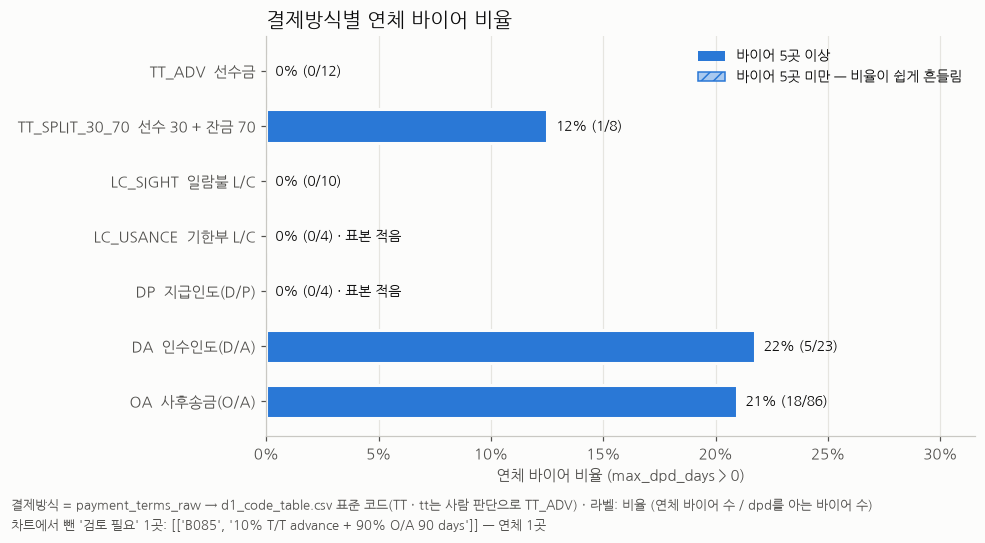

| 결제방식 | 바이어 수 | dpd 모름 | 연체 바이어 수 | 연체 바이어 비율 (= 연체 ÷ (바이어 − dpd 모름)) |
|---|---:|---:|---:|---:|
| TT_ADV 선수금 | 12 | 0 | 0 | 0.0% (0 ÷ 12) |
| TT_SPLIT_30_70 선수 30 + 잔금 70 | 8 | 0 | 1 | 12.5% (1 ÷ 8) |
| LC_SIGHT 일람불 L/C | 10 | 0 | 0 | 0.0% (0 ÷ 10) |
| LC_USANCE 기한부 L/C | 4 | 0 | 0 | 0.0% (0 ÷ 4) |
| DP 지급인도(D/P) | 4 | 0 | 0 | 0.0% (0 ÷ 4) |
| DA 인수인도(D/A) | 24 | 1 | 5 | 21.7% (5 ÷ 23) |
| OA 사후송금(O/A) | 87 | 1 | 18 | 20.9% (18 ÷ 86) |
| 검토 필요 코드 미정 | 1 | 0 | 1 | 100.0% (1 ÷ 1) |
| **합계** | 150 | 2 | 25 | 16.9% (25 ÷ 148) |

코드별 연체 바이어의 dpd: {'DA': [10, 27, 61, 355, 381], 'OA': [3, 3, 5, 12, 13, 15, 19, 27, 27, 31, 36, 48, 70, 74, 89, 90, 269, 305], 'TT_SPLIT_30_70': [32], '검토 필요': [22]}
dpd 모름의 결제방식: [['B058', 'OA'], ['B066', 'DA']]


In [5]:
# 5. 차트 3 — 결제방식(표준 코드)별 연체 바이어 비율. 순서는 수출자 위험이 낮은 것 → 높은 것(코드표 순)
# '검토 필요'(코드 미정 1곳)는 비율이 1/1이라 축을 왜곡하므로 차트에서 빼고 각주 · 표에만 남긴다
METHOD_ORDER = ["TT_ADV", "TT_SPLIT_30_70", "LC_SIGHT", "LC_USANCE", "DP", "DA", "OA", "검토 필요"]
METHOD_KO = {"TT_ADV": "선수금", "TT_SPLIT_30_70": "선수 30 + 잔금 70", "LC_SIGHT": "일람불 L/C", "LC_USANCE": "기한부 L/C",
             "DP": "지급인도(D/P)", "DA": "인수인도(D/A)", "OA": "사후송금(O/A)", "검토 필요": "코드 미정"}
by_method = overdue_rate(df, "pay_method").reindex(METHOD_ORDER)
plot = by_method.drop(index="검토 필요")
review = by_method.loc["검토 필요"]
review_ids = df.loc[df["pay_method"].eq("검토 필요"), ["buyer_id", "payment_terms_raw"]].values.tolist()
small = plot["분모(dpd 확인)"] < MIN_N

fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(plot))[::-1]
ax.barh(y, plot["연체 비율"], height=0.6, color=np.where(small, "#a9c9ef", BLUE), edgecolor=SURFACE, linewidth=2)
for yi, (code, r) in zip(y, plot.iterrows()):
    if r["분모(dpd 확인)"] < MIN_N:
        ax.barh(yi, r["연체 비율"], height=0.6, color="none", edgecolor=BLUE, hatch="///", linewidth=0)
    note = " · 표본 적음" if r["분모(dpd 확인)"] < MIN_N else ""
    ax.text(r["연체 비율"] + 0.004, yi, f"{r['연체 비율']:.0%} ({int(r['연체 바이어 수'])}/{int(r['분모(dpd 확인)'])}){note}",
            va="center", fontsize=9, color=INK)
ax.set_yticks(y, [f"{c}  {METHOD_KO[c]}" for c in plot.index])
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, plot["연체 비율"].max() * 1.45)
ax.grid(axis="y", visible=False)
ax.set_xlabel("연체 바이어 비율 (max_dpd_days > 0)")
ax.legend(handles=[Patch(facecolor=BLUE, label=f"바이어 {MIN_N}곳 이상"),
                   Patch(facecolor="#a9c9ef", edgecolor=BLUE, hatch="///", label=f"바이어 {MIN_N}곳 미만 — 비율이 쉽게 흔들림")],
          loc="upper right", fontsize=9, frameon=False)
ax.set_title("결제방식별 연체 바이어 비율", loc="left", fontsize=13)
fig.text(0.01, -0.02, "결제방식 = payment_terms_raw → d1_code_table.csv 표준 코드(TT · tt는 사람 판단으로 TT_ADV) · "
         "라벨: 비율 (연체 바이어 수 / dpd를 아는 바이어 수)", fontsize=8.5, color=MUTED)
fig.text(0.01, -0.06, f"차트에서 뺀 '검토 필요' {int(review['바이어 수'])}곳: {review_ids} — "
         f"연체 {int(review['연체 바이어 수'])}곳", fontsize=8.5, color=MUTED)
fig.tight_layout()
fig.savefig(CHARTS / "d1_chart3_method_overdue.png")
plt.show()

# d1_eda_notes.md에 옮길 표 — 결제방식별 바이어 수 · 연체 바이어 수 · 연체 바이어 비율
print("| 결제방식 | 바이어 수 | dpd 모름 | 연체 바이어 수 | 연체 바이어 비율 (= 연체 ÷ (바이어 − dpd 모름)) |")
print("|---|---:|---:|---:|---:|")
for code, r in list(by_method.iterrows()) + [("합계", by_method.sum())]:
    n, unk, od, den = (int(r[k]) for k in ["바이어 수", "dpd 모름", "연체 바이어 수", "분모(dpd 확인)"])
    label = "**합계**" if code == "합계" else f"{code} {METHOD_KO[code]}"
    print(f"| {label} | {n} | {unk} | {od} | {od / den:.1%} ({od} ÷ {den}) |")
print("\n코드별 연체 바이어의 dpd:", df[df["is_overdue"].fillna(False)].groupby("pay_method")["dpd"].apply(lambda s: sorted(s.astype(int))).to_dict())
print("dpd 모름의 결제방식:", df.loc[df["dpd"].isna(), ["buyer_id", "pay_method"]].values.tolist())

**차트 3 해석** (숫자는 바로 위 셀 출력 표)
1. 외상 조건인 DA 21.7%(5 ÷ 23)와 OA 20.9%(18 ÷ 86)에만 연체가 몰려 있다. 연체 바이어 25곳 중 23곳이 이 두 방식이다.
2. 선수금(0/12)과 일람불 L/C(0/10)는 연체가 없다. 기한부 L/C와 D/P(각 0/4)도 0이지만 표본이 적다. 선수 30 + 잔금 70은 1곳(B087, 32일)이 연체 중이다.
3. DA는 비율이 OA와 비슷하지만, 91일 이상 장기 연체가 2곳(355 · 381일)으로 23곳 중 2곳이다. OA는 86곳 중 2곳(269 · 305일)이다. 차트에서 뺀 '검토 필요' B085(10% 선수 + 90% O/A 90일)도 22일 연체 중이라 코드를 정해야 한다.